# Module 7 — Pretrained Models and the Hugging Face Ecosystem

## Lesson 7.5 — Building Applications with Pretrained Models


A model is not a product. A sentiment model that scores well on a validation set is a capability; a feature that tells a business which customer reviews to read first is an application. Between the two sits a lot of engineering. The application has to decide what inputs to accept, what to do with inputs it was never designed for, when to answer and when to say "I'm not sure", and how to measure whether the whole system, not just the model, does its job.

This note is the practical heart of Module 7. We build four small applications from four pretrained models, each a few lines of code thanks to Notes 7.1–7.4: sentiment analysis of film reviews, text generation, semantic search with sentence embeddings, and zero-shot image classification and search with CLIP. For each one we look as hard at where it fails as at where it works. Then we wrap the sentiment model in a reusable service that checks its inputs, recognises text that isn't a film review, and declines to answer when unsure, and we evaluate that service the way you would evaluate a real feature.

**Key question:** *How do we turn a pretrained model's capability into a feature that behaves sensibly on real, messy inputs?*

### Learning objectives
- test a classifier on clear, ambiguous, negated and out-of-distribution inputs, and explain what its confidence does and doesn't tell you;
- generate text with a pretrained language model and compare greedy decoding, temperature, top-k and top-p;
- build a semantic search over documents with sentence embeddings, and explain what those embeddings capture;
- use CLIP for zero-shot image classification and text-to-image search, choosing its settings on held-out data;
- design an inference service that validates inputs, handles errors, flags out-of-domain text and abstains when unsure;
- evaluate an application with coverage, accuracy on answered inputs and a confusion matrix.

### Prerequisites

 read Notes 7.1–7.4. You'll also draw on earlier notes: the negation test from Note 5.3, the toy CLIP from Note 5.5, and the decoding strategies from Note 6.6.

### Setup

This note loads four models in turn: the sentiment model, distilgpt2, MiniLM and CLIP. Each is deleted once its section is finished, to keep memory use down. The first run downloads well over a gigabyte in total, so it takes a while; later runs use the cache. The usual harmless warnings appear (TqdmWarning, the unauthenticated-request message and, on a Mac, a few `W…` lines).

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

In [1]:
import os, gc, gzip, time, hashlib, urllib.request
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
from transformers import (pipeline, AutoTokenizer, AutoModel, AutoModelForCausalLM,
                          CLIPModel, CLIPProcessor)

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1017 13:44:59.822000 77057 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 13:44:59.908000 77057 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 13:44:59.927000 77057 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch 2.14.1 | device: cpu


## 1. The Big Picture: Turning Model Capabilities into Features

Every application in this note has the same structure. A pretrained model supplies one **capability**, a function from an input to an output. The application wraps it with everything a user needs:

- **Input handling:** what counts as a valid input, and what happens to one that isn't (empty text, the wrong type, a 100-page document).
- **Fit checks:** is this input the *kind* of thing the model was built for? A film-review classifier will happily score a password-reset request; the application should notice.
- **Decision rules:** when to answer, and when to hold back, for example by passing uncertain cases to a person.
- **Evaluation:** measured on the whole system, with the numbers a product owner cares about: how often it answers, and how often it's right when it does.

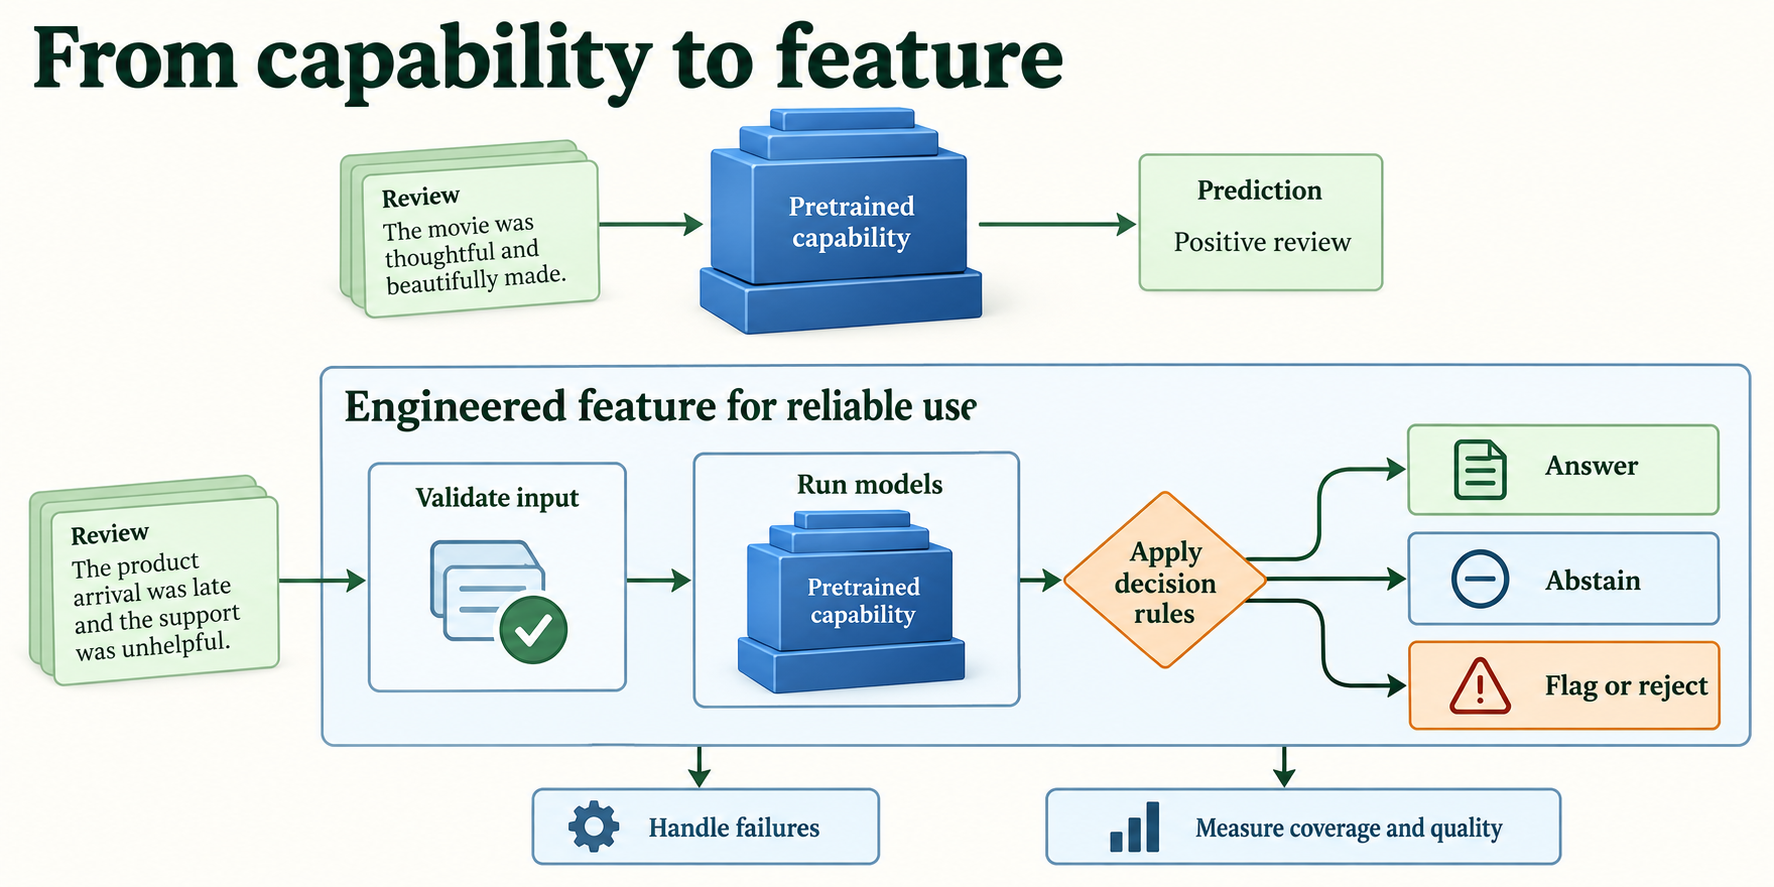

*Figure 7.5.1. An application adds input validation, decision rules, error handling and measured quality to a pretrained capability. The OOD check is a heuristic to validate, not a guarantee.*

All the IMDb work uses the fixed split from Note 7.1. The function is copied here, and the fingerprints confirm the same reviews.

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


## 2. Practice: IMDb Sentiment Classification

### 2.1 The aggregate

We start from the sentiment model and measure it on the 1,000 `val_eval` reviews. The helper `positive_prob` returns each text's probability of being positive. It sorts texts by length before batching, to cut padding (Note 7.4, Section 6), and puts the results back in the original order.

In [4]:
SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
clf = pipeline("text-classification", model=SST2, device=device, revision=MODEL_REVISIONS.get(SST2))

def positive_prob(texts, batch_size=32):
    order = np.argsort([len(t) for t in texts])                       # similar lengths together: less padding (Note 7.4)
    out = clf([texts[i] for i in order], truncation=True, max_length=256, batch_size=batch_size)
    p = np.empty(len(texts))
    p[order] = [o["score"] if o["label"] == "POSITIVE" else 1 - o["score"] for o in out]   # back to the original order
    return p                                                          # P(positive) for each text

val_x, val_y = imdb["val_eval"]
val_p = positive_prob(val_x)
print(f"val_eval: {len(val_x)} reviews | accuracy {((val_p > 0.5) == val_y).mean():.3f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 21022.05it/s]

val_eval: 1000 reviews | accuracy 0.882


The model scores 0.882 on the validation reviews. That's the aggregate. An application meets individual inputs, so let's look at those.

### 2.2 Individual inputs

We test five groups of inputs, written before running the model: clearly positive, clearly negative, ambiguous (mixed or lukewarm), the four negation sentences from Note 5.3, and inputs that are not film reviews at all.

In [5]:
probes = {
    "positive":            ["An absolute triumph. I loved every minute of it.",
                            "Gorgeous to look at and genuinely moving."],
    "negative":            ["Dull, predictable and far too long.",
                            "I walked out after forty minutes."],
    "ambiguous":           ["The acting was superb, but the story made no sense.",
                            "Not as bad as the critics said, but not good either.",
                            "It was fine, I guess."],
    "negation (Note 5.3)": ["the movie was good", "the movie was not good",
                            "the movie was bad", "the movie was not bad"],
    "out of distribution": ["asdkjh qwe zzz", "The parcel arrived on Tuesday.",
                            "Le film était magnifique.", "Please reset my password."],
}
for group, sentences in probes.items():
    print(group)
    for s, p in zip(sentences, positive_prob(sentences)):
        print(f"   P(positive) = {p:.3f}  {s}")

positive
   P(positive) = 1.000  An absolute triumph. I loved every minute of it.
   P(positive) = 1.000  Gorgeous to look at and genuinely moving.
negative
   P(positive) = 0.000  Dull, predictable and far too long.
   P(positive) = 0.000  I walked out after forty minutes.
ambiguous
   P(positive) = 0.001  The acting was superb, but the story made no sense.
   P(positive) = 0.003  Not as bad as the critics said, but not good either.
   P(positive) = 1.000  It was fine, I guess.
negation (Note 5.3)
   P(positive) = 1.000  the movie was good
   P(positive) = 0.000  the movie was not good
   P(positive) = 0.000  the movie was bad
   P(positive) = 0.999  the movie was not bad
out of distribution
   P(positive) = 0.004  asdkjh qwe zzz
   P(positive) = 0.586  The parcel arrived on Tuesday.
   P(positive) = 0.928  Le film était magnifique.
   P(positive) = 0.011  Please reset my password.


Read the groups one at a time.

- **Clear inputs** get confident, correct answers (1.000 and 0.000).
- **Negation, which defeated Note 5.3's model, is handled correctly.** There, a bag-of-embeddings model averaged word vectors, so "not good" still looked positive. Here, "the movie was not good" gets 0.000 and "the movie was not bad" gets 0.999. A Transformer reads words in context, so "not" changes the meaning of the word after it.
- **Ambiguous inputs get confident answers too, and that's a problem.** "The acting was superb, but the story made no sense" gets 0.001: the model reads the "but" clause as decisive, which is defensible. But "It was fine, I guess." gets 1.000 positive, and "Not as bad as the critics said, but not good either" gets 0.003. A human would call these lukewarm. The model, fine-tuned on sentences labelled only positive or negative, has no way to say "in between", and pushes them to an extreme with near-total confidence.
- **Out-of-distribution inputs get answers anyway.** The gibberish "asdkjh qwe zzz" is called negative with P(positive) = 0.004, a confidence of 0.996. "Please reset my password." gets 0.011. Only "The parcel arrived on Tuesday." gets an uncertain-looking 0.586. (The French review gets 0.928, positive, which happens to be correct. The model was trained on English, so don't count on that: it may simply be reacting to words like "film" that look the same in both languages.)

The lesson for the application is the most important point in this note: **a high confidence score does not mean the input made sense.** The model's probabilities describe how strongly an input resembles one class *compared with the other*, not whether it belongs to the model's world at all. Section 6 builds a separate check for that.

> **Key terms**
> - **Capability:** what a model can compute from an input, such as a probability of positive sentiment.
> - **Out-of-distribution (OOD) input:** an input unlike the data a model was trained on.
> - **Confidence:** the probability a classifier gives to its chosen class; here, the larger of P(positive) and 1 − P(positive).

**Check yourself.**

1. The model gave "asdkjh qwe zzz" a confidence of 0.996. Why can't a two-class softmax ever say "this isn't a review"?

<details>
<summary>Worked answer</summary>

A two-class softmax always splits a probability of 1 between "positive" and "negative"; there's no third option for "neither". The output only compares the two classes with each other, so any input, even gibberish, is pushed towards whichever class its features resemble slightly more, and the softmax can make that look very confident. Detecting that an input doesn't belong needs a separate signal, such as the review-likeness check in Section 6.

</details>

## 3. Practice: Text Generation with a Small Pretrained Model

In Note 6.6 you generated Shakespeare-like text with your own small Transformer and compared decoding strategies. Here we do the same with distilgpt2, a pretrained language model trained on web text. Generating text is a loop: predict a probability for every possible next token, choose one, append it, repeat. The interesting choice is *how* to choose.

### 3.1 Temperature reshapes the distribution

First, let's look at the model's probabilities for the token after "The movie was", and how **temperature** changes them. Logits are divided by the temperature T before the softmax: T below 1 sharpens the distribution towards the top choices, T above 1 flattens it.

In [6]:
GPT = "distilbert/distilgpt2"
gen_tok = AutoTokenizer.from_pretrained(GPT, revision=MODEL_REVISIONS.get(GPT))
gen_model = AutoModelForCausalLM.from_pretrained(GPT, revision=MODEL_REVISIONS.get(GPT)).to(device).eval()

enc = gen_tok("The movie was", return_tensors="pt").to(device)
with torch.inference_mode():
    next_logits = gen_model(**enc).logits[0, -1]                     # (50257,) scores for the next token
for T in (0.7, 1.0, 1.5):
    p = (next_logits / T).softmax(-1)
    top = p.topk(5)
    print(f"T = {T}: " + ", ".join(f"{gen_tok.decode(int(i))!r} {v:.3f}" for v, i in zip(top.values, top.indices)),
          f"| top-5 total {top.values.sum():.3f}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 12301.91it/s]

T = 0.7: ' a' 0.148, ' released' 0.134, ' made' 0.110, ' shot' 0.108, ' the' 0.041 | top-5 total 0.540
T = 1.0: ' a' 0.067, ' released' 0.063, ' made' 0.055, ' shot' 0.054, ' the' 0.027 | top-5 total 0.267
T = 1.5: ' a' 0.017, ' released' 0.017, ' made' 0.015, ' shot' 0.015, ' the' 0.010 | top-5 total 0.074


At T = 1.0, the model's own distribution, the top choice " a" has probability 0.067, and the top five tokens together hold only 0.267. Most of the probability is spread over thousands of other tokens. At T = 0.7, the same five tokens hold 0.540; at T = 1.5, only 0.074. The order never changes, only how sharply the probability is concentrated.

### 3.2 Four ways to choose

We compare four strategies from Note 6.6, each continuing "The movie was" for 40 tokens:
- **greedy:** always take the most likely token;
- **temperature 0.7:** sample from the sharpened distribution;
- **top-k 40:** sample from the 40 most likely tokens only;
- **top-p 0.9:** sample from the smallest set of tokens whose probabilities add up to 0.9 (also called nucleus sampling).

Sampling is random, so we fix the seed before each call. That way you get the same text as these notes.

In [7]:
strategies = {"greedy":          dict(do_sample=False),
              "temperature 0.7": dict(do_sample=True, temperature=0.7, top_k=0),
              "top-k 40":        dict(do_sample=True, top_k=40),
              "top-p 0.9":       dict(do_sample=True, top_p=0.9, top_k=0)}

def generate(prompt, seed, **settings):
    torch.manual_seed(seed)                                           # sampling is random: fix the seed
    enc = gen_tok(prompt, return_tensors="pt").to(device)
    with torch.inference_mode():
        out = gen_model.generate(**enc, max_new_tokens=40, pad_token_id=gen_tok.eos_token_id, **settings)
    return gen_tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True)   # new text only

for name, settings in strategies.items():
    print(f"{name:<16} The movie was{generate('The movie was', seed=0, **settings)!r}")

greedy           The movie was' a hit in the United States and was a hit in the United Kingdom.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


temperature 0.7  The movie was' a gritty pilot with a very well-thought out story, the story that the protagonist had to live with.\n\n\n\nThe film was a tough one, however, and he had to act'


top-k 40         The movie was' a wonderful, funny and hilarious movie, directed by J.J. Abrams.\n\n\n\n"It looked like I should have finished a lot of the films in a better way," Laffer'


top-p 0.9        The movie was' a gritty pilot with pretty much every scene, the scenes are the same, the stakes are fantastic and the production is scary. However, so far, it’ve been very successful.With an'


Greedy decoding produces one fluent clause ("a hit in the United States and was a hit in the United Kingdom", already repeating itself), then gets stuck emitting blank lines (`\n`) until it runs out of tokens. Once a blank line is the most likely next token, it stays the most likely next token. The sampled versions are more varied and readable, though not exactly sensible: distilgpt2 invents a "gritty pilot" and a quote from someone called Laffer. The model has learned what film writing *sounds* like, not what is true (the same lesson as Note 7.1, Section 3).

One sample per strategy proves little, so let's measure repetition over several prompts and seeds. We count the share of 3-word sequences that repeat earlier ones in the same text: 0 means no repetition.

In [8]:
def repeated_trigram_share(text):
    words = text.split()
    grams = [tuple(words[i:i + 3]) for i in range(len(words) - 2)]
    return 1 - len(set(grams)) / max(len(grams), 1)                  # 0 = no 3-word sequence repeats

prompts = ["The movie was", "My favourite film of all time is", "The director's latest work"]
for name, settings in strategies.items():
    seeds = [0] if name == "greedy" else range(3)                    # greedy is the same for every seed
    shares = [repeated_trigram_share(generate(p, s, **settings)) for p in prompts for s in seeds]
    print(f"{name:<16} repeated 3-word sequences: mean {np.mean(shares):.2f} | min {min(shares):.2f} | max {max(shares):.2f} | {len(shares)} texts")
del gen_model; _ = gc.collect()

greedy           repeated 3-word sequences: mean 0.18 | min 0.00 | max 0.30 | 3 texts


temperature 0.7  repeated 3-word sequences: mean 0.00 | min 0.00 | max 0.00 | 9 texts


top-k 40         repeated 3-word sequences: mean 0.00 | min 0.00 | max 0.00 | 9 texts


top-p 0.9        repeated 3-word sequences: mean 0.00 | min 0.00 | max 0.00 | 9 texts


Greedy decoding repeats itself in its texts (a mean of 0.18, up to 0.30), while none of the 9 sampled texts for any sampling strategy repeats a 3-word sequence. (Our measure counts words, so greedy's runs of blank lines aren't even included; its real repetition is worse.) For open-ended writing, sampling with a moderate temperature, top-k or top-p is the usual choice. For tasks with one right answer, such as extracting a date, greedy is often better, because variety is not wanted.

> **Key terms**
> - **Temperature:** a number that divides the logits before softmax; below 1 sharpens the distribution, above 1 flattens it.
> - **Top-k sampling:** sampling only from the k most likely tokens.
> - **Top-p (nucleus) sampling:** sampling only from the smallest set of tokens whose probabilities sum to at least p.
> - **Degenerate repetition:** a generator getting stuck repeating the same words or tokens.

> **Common mistake:** comparing decoding strategies on a single sample each. Sampling is random: one lucky or unlucky sample says little. Fix the seeds and compare several prompts and samples.

**Check yourself.**

1. Why does greedy decoding get stuck in loops, while sampling usually escapes them?

<details>
<summary>Worked answer</summary>

Greedy decoding is deterministic: the same context always gives the same next token. Once the text enters a pattern where the pattern itself makes the next repeat most likely (as with the blank lines), greedy has no way out. Sampling sometimes picks a less likely token, which changes the context and lets the text move on.

</details>

## 4. Practice: Pretrained Embeddings for Semantic Similarity

### 4.1 What the embeddings capture

A **sentence-embedding model** turns a whole text into one vector, so that texts with similar meanings get nearby vectors. We use all-MiniLM-L6-v2 (Note 7.3), with the pooling it was trained for: the average of its token vectors, ignoring padding. Each vector is then scaled to length 1, so a dot product between two vectors equals their cosine similarity.

In [9]:
MINILM = "sentence-transformers/all-MiniLM-L6-v2"
emb_tok = AutoTokenizer.from_pretrained(MINILM, revision=MODEL_REVISIONS.get(MINILM))
emb_model = AutoModel.from_pretrained(MINILM, revision=MODEL_REVISIONS.get(MINILM)).to(device).eval()

def embed(texts, batch_size=64, max_length=128):
    """One unit-length vector per text: the mean of its token vectors (the model's intended pooling)."""
    out = []
    with torch.inference_mode():
        for i in range(0, len(texts), batch_size):
            enc = emb_tok(texts[i:i + batch_size], truncation=True, max_length=max_length,
                          padding=True, return_tensors="pt").to(device)
            tokens = emb_model(**enc).last_hidden_state                  # (B, T, 384)
            mask = enc["attention_mask"].unsqueeze(-1).float()           # (B, T, 1): 1 = real token
            mean = (tokens * mask).sum(1) / mask.sum(1)                  # (B, 384): average of real tokens
            out.append(F.normalize(mean, dim=-1).cpu())                  # length 1, so dot product = cosine
    return torch.cat(out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8681.59it/s]

In Note 5.3 we found that *embeddings learn what their objective rewards*: vectors trained to predict sentiment grouped words by sentiment, while vectors trained to predict neighbouring words grouped them by topic. Let's ask what MiniLM's vectors reward. We compare one sentence with four others:

In [10]:
anchor = "A thrilling, beautifully acted film."
others = {"paraphrase":                       "An exciting movie with superb performances.",
          "same topic, opposite sentiment":   "A dull, badly acted film.",
          "same sentiment, different topic":  "A delicious, beautifully cooked meal.",
          "unrelated":                        "The parcel arrived on Tuesday."}
vecs = embed([anchor] + list(others.values()))
for (kind, text), v in zip(others.items(), vecs[1:]):
    print(f"{kind:<33} cosine {float(vecs[0] @ v):.3f}  {text}")

paraphrase                        cosine 0.734  An exciting movie with superb performances.
same topic, opposite sentiment    cosine 0.737  A dull, badly acted film.
same sentiment, different topic   cosine 0.344  A delicious, beautifully cooked meal.
unrelated                         cosine -0.007  The parcel arrived on Tuesday.


The paraphrase scores 0.734, as expected. But "A dull, badly acted film" scores 0.737, as high or higher, even though it says the opposite. Meanwhile "A delicious, beautifully cooked meal", which shares the positive sentiment and even the word "beautifully", scores only 0.344. MiniLM was trained to bring together texts *about the same thing*, such as a question and its answer, or two descriptions of the same event. So its vectors capture topic far more than opinion. That's exactly what search needs, but it means these embeddings, used as they are, are a poor way to measure sentiment.

### 4.2 Semantic search

Search is the classic use: embed a collection of documents once, embed each query, and return the documents whose vectors are closest. We embed the first 1,000 training reviews and try three queries written before running.

In [11]:
corpus_x, corpus_y = imdb["train"][0][:1000], imdb["train"][1][:1000]    # the first 1,000 training reviews
corpus = embed(corpus_x)                                                   # (1000, 384)
print("corpus:", tuple(corpus.shape))
queries = ["a heartwarming story about a family",
           "terrible special effects and wooden acting",
           "a horror film that kept me awake at night"]
for q, qv in zip(queries, embed(queries)):
    scores = corpus @ qv                                                   # (1000,) cosine with every review
    print(f"\nquery: {q!r}")
    for i in scores.topk(3).indices.tolist():
        print(f"  {scores[i]:.3f} | {'pos' if corpus_y[i] else 'neg'} | {corpus_x[i][:110]}...")

corpus: (1000, 384)

query: 'a heartwarming story about a family'
  0.482 | pos | This film is moving without being sentimental - meaningful without being pretentious. It tells a simple story ...
  0.444 | pos | This is arguably John Thaw's finest performance where he successfully shakes off any traits of his Inspector M...
  0.440 | pos | The autobiography on which this movie is based remains one of the most heart-rending books I have ever read. I...

query: 'terrible special effects and wooden acting'
  0.648 | neg | Where to begin? the special effects should be named special defects, When the director shouted "action" I gues...
  0.595 | neg | Budget, decent actors ...who knew these things were important. Don't waste your time on this piece of junk. Th...
  0.590 | pos | I just got this video used and I was watching it last night. The acting started out extremely bad (hey------he...

query: 'a horror film that kept me awake at night'
  0.604 | pos | My personal favorite horror film.

The results match the *meaning* of the queries, not their exact words. The best match for "terrible special effects and wooden acting" says the special effects "should be named special defects" without using the word "terrible". For "a heartwarming story about a family", all three are moving, positive reviews. As in Section 4.1, the search finds topics, not opinions: the horror query returns one review that loved its film and two that hated theirs, and one of the "terrible special effects" results is a positive review that mentions bad acting at the start.

> **Key terms**
> - **Sentence-embedding model:** a model that maps a text to one vector, placing similar meanings close together.
> - **Mean pooling:** averaging a text's token vectors (ignoring padding) to get one vector for the whole text.
> - **Semantic search:** retrieving documents by similarity of meaning, using embeddings, rather than by matching words.

**Check yourself.**

1. A colleague wants to use MiniLM similarity to find reviews that "agree" with a given review. Based on Section 4.1, what would go wrong?

<details>
<summary>Worked answer</summary>

MiniLM similarity mostly measures topic. Reviews of the same film, or of similar films, would score as similar whether they agree or disagree. Section 4.1's opposite-sentiment sentence scored 0.737, as high as a true paraphrase. To find reviews that agree, you'd need to combine similarity with a sentiment signal, or use a model trained to compare stances.

</details>

## 5. Practice: CLIP for Zero-Shot Image Classification and Text-to-Image Retrieval

### 5.1 From the toy to the real thing

In Note 5.5 you built a toy version of CLIP: an image encoder and a text encoder trained so that matching image–caption pairs had similar vectors. It worked, but it could only recognise what its small training set described. Trained without sneakers, it matched sneaker images to "sandal" and "ankle boot". The real CLIP was trained the same way on an enormous collection of images and captions from the web. That lets it do **zero-shot classification**: we write each class as a sentence ("a photo of a sneaker."), embed the sentences, and give each image the class whose sentence is most similar. No training on our classes at all.

We use the Fashion-MNIST test file from Module 5. Fashion-MNIST images are tiny (28 × 28), greyscale and drawn light-on-dark, very unlike CLIP's web photos, so two settings may matter: whether to **invert** the images to dark-on-white, and how to word the class **template**. To choose them fairly, we use two separate sets of images: the first 300 to choose settings, and 1,000 others to report the result.

In [12]:
os.makedirs("data/fashion", exist_ok=True)
base = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
for f in ["t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]:
    if not os.path.exists(f"data/fashion/{f}"):
        urllib.request.urlretrieve(base + f, f"data/fashion/{f}")
images = np.frombuffer(gzip.open("data/fashion/t10k-images-idx3-ubyte.gz").read(), np.uint8, offset=16).reshape(-1, 28, 28)
targets = np.frombuffer(gzip.open("data/fashion/t10k-labels-idx1-ubyte.gz").read(), np.uint8, offset=8)
classes = ["T-shirt/top", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]
choose_idx, test_idx = np.arange(0, 300), np.arange(1000, 2000)          # two disjoint sets of images
print(images.shape, "| choosing on", len(choose_idx), "images | reporting on", len(test_idx), "images")

(10000, 28, 28) | choosing on 300 images | reporting on 1000 images


In [13]:
CLIP = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(CLIP, revision=MODEL_REVISIONS.get(CLIP)).to(device).eval()               # downloads about 605 MB the first time
proc = CLIPProcessor.from_pretrained(CLIP, revision=MODEL_REVISIONS.get(CLIP))

def image_vectors(idx, invert):
    vecs = []
    with torch.inference_mode():
        for i in range(0, len(idx), 100):
            pics = [Image.fromarray(255 - images[j] if invert else images[j]).convert("RGB") for j in idx[i:i + 100]]
            out = clip.get_image_features(**proc(images=pics, return_tensors="pt").to(device))
            vecs.append(F.normalize(out.pooler_output, dim=-1).cpu())      # (100, 512) in the shared space
    return torch.cat(vecs)

def text_vectors(texts):
    with torch.inference_mode():
        out = clip.get_text_features(**proc(text=texts, return_tensors="pt", padding=True).to(device))
    return F.normalize(out.pooler_output, dim=-1).cpu()                     # (len(texts), 512)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 59129.11it/s]

### 5.2 Choosing settings on held-out images

We try both settings on the 300 choosing images and keep the best combination.

In [14]:
templates = ["a photo of a {}.", "a black and white photo of a {}."]
choose_vecs = {inv: image_vectors(choose_idx, inv) for inv in (False, True)}
results = {}
for inv in (False, True):
    for tpl in templates:
        pred = (choose_vecs[inv] @ text_vectors([tpl.format(c) for c in classes]).T).argmax(1).numpy()
        results[(inv, tpl)] = (pred == targets[choose_idx]).mean()
        print(f"inverted={str(inv):<5} template={tpl!r:<36} accuracy {results[(inv, tpl)]:.3f}")
best_inv, best_tpl = max(results, key=results.get)
print(f"chosen on the {len(choose_idx)} choosing images:", "inverted" if best_inv else "as given", "|", repr(best_tpl))

inverted=False template='a photo of a {}.'                   accuracy 0.633
inverted=False template='a black and white photo of a {}.'   accuracy 0.690
inverted=True  template='a photo of a {}.'                   accuracy 0.723
inverted=True  template='a black and white photo of a {}.'   accuracy 0.750
chosen on the 300 choosing images: inverted | 'a black and white photo of a {}.'


Both changes help: inverting the images to dark-on-white, like a product photo, and describing them as black-and-white photos. The best combination scores 0.750 on the choosing images, against 0.633 for the plain setup. Now we use that combination, once, on the 1,000 reporting images:

In [15]:
test_vecs = image_vectors(test_idx, best_inv)
class_vecs = text_vectors([best_tpl.format(c) for c in classes])
test_pred = (test_vecs @ class_vecs.T).argmax(1).numpy()
test_true = targets[test_idx]
print(f"zero-shot accuracy on {len(test_idx)} new images: {(test_pred == test_true).mean():.3f} (chance 0.100)")
for c, name in enumerate(classes):
    mask = test_true == c
    wrong = np.bincount(test_pred[mask & (test_pred != c)], minlength=10)
    note = f" | most often mistaken for {classes[wrong.argmax()]}" if wrong.sum() else ""
    print(f"  {name:<12} {mask.sum():>3} images | accuracy {(test_pred[mask] == c).mean():.2f}{note}")

zero-shot accuracy on 1000 new images: 0.733 (chance 0.100)
  T-shirt/top   93 images | accuracy 0.59 | most often mistaken for dress
  trouser       98 images | accuracy 0.98 | most often mistaken for coat
  pullover     103 images | accuracy 0.91 | most often mistaken for coat
  dress         97 images | accuracy 0.48 | most often mistaken for coat
  coat         104 images | accuracy 0.65 | most often mistaken for pullover
  sandal       108 images | accuracy 0.83 | most often mistaken for ankle boot
  shirt        100 images | accuracy 0.15 | most often mistaken for pullover
  sneaker      105 images | accuracy 0.79 | most often mistaken for sandal
  bag           99 images | accuracy 0.98 | most often mistaken for pullover
  ankle boot    93 images | accuracy 0.95 | most often mistaken for sneaker


CLIP classifies 0.733 of the 1,000 new images correctly, against 0.100 by chance, with no training on Fashion-MNIST at all. The result on the reporting images is close to the 0.750 seen on the choosing images, as it should be when settings are chosen fairly.

The per-class results tell the real story:
- **Sneakers, the class Note 5.5's toy could not recognise, are recognised 0.79 of the time.** CLIP learned what a sneaker is from the web, not from our data.
- **Trousers and bags are almost perfect (0.98).** They have distinctive shapes.
- **Shirts nearly always fail (0.15),** most often called pullovers, and dresses manage only 0.48. At 28 × 28 pixels in greyscale, a shirt, a T-shirt, a pullover and a coat really are hard to tell apart. Their differences (buttons, collars, fabric) are mostly lost at this size.

### 5.3 Text-to-image search

Because images and text share one space, we can also search images with words: embed a query sentence and return the closest images.

query 'a black and white photo of a sneaker.': 4 of the top 5 are 'sneaker' | returned: ['sneaker', 'sneaker', 'sneaker', 'sneaker', 'sandal']
query 'a black and white photo of a bag.': 4 of the top 5 are 'bag' | returned: ['bag', 'bag', 'bag', 'bag', 'shirt']
query 'a black and white photo of a dress.': 4 of the top 5 are 'dress' | returned: ['dress', 'dress', 'dress', 'T-shirt/top', 'dress']
query 'a black and white photo of a shirt.': 2 of the top 5 are 'shirt' | returned: ['T-shirt/top', 'shirt', 'T-shirt/top', 'T-shirt/top', 'shirt']


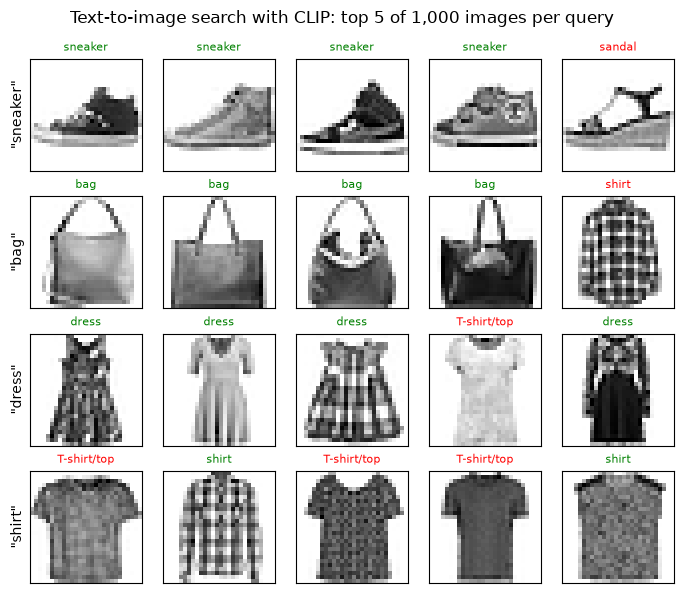

In [16]:
search = ["sneaker", "bag", "dress", "shirt"]
fig, axes = plt.subplots(len(search), 5, figsize=(7, 6))
for row, word in enumerate(search):
    scores = test_vecs @ text_vectors([best_tpl.format(word)])[0]          # (1000,) similarity to the query
    top = scores.topk(5).indices.numpy()
    hits = (test_true[top] == classes.index(word)).sum()
    print(f"query {best_tpl.format(word)!r}: {hits} of the top 5 are {word!r} | returned: {[classes[t] for t in test_true[top]]}")
    for k, j in enumerate(top):
        ax = axes[row, k]
        ax.imshow(images[test_idx[j]], cmap="gray_r" if best_inv else "gray"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(classes[test_true[j]], fontsize=8, color="green" if test_true[j] == classes.index(word) else "red")
    axes[row, 0].set_ylabel(f'"{word}"', fontsize=10)
plt.suptitle("Text-to-image search with CLIP: top 5 of 1,000 images per query"); plt.tight_layout(); plt.show()
del clip; _ = gc.collect()

For "sneaker", "bag" and "dress", 4 of the top 5 images are right. The mistakes are understandable: a sandal for "sneaker", a T-shirt for "dress", and a plaid shirt for "bag". For "shirt", only 2 of the top 5 are shirts and the other three are T-shirts, the same confusion the per-class numbers showed. In the dataset's labels a T-shirt and a shirt are different classes, but in everyday English the word "shirt" covers both, and CLIP learned its idea of a "shirt" from everyday English.

> **Key terms**
> - **Zero-shot classification:** classifying into classes the model was never trained on, by describing each class in words.
> - **Prompt template:** the sentence pattern used to describe each class, such as "a photo of a {}.".
> - **Text-to-image retrieval:** finding the images whose embeddings are closest to a text query's embedding.

> **Common mistake:** choosing a template or preprocessing step on the same images you report. Trying several settings and reporting the best one on the same data overstates accuracy. Choose on one set, report on another, as we did with the 300 and the 1,000.

**Check yourself.**

1. Our zero-shot CLIP reached 0.733 on Fashion-MNIST; a small CNN trained on Fashion-MNIST in Module 5 did better. When would you still choose CLIP?

<details>
<summary>Worked answer</summary>

When you have no labelled data for your classes, or the classes change often. CLIP needs only a sentence per class, so a new category ("a photo of a raincoat") can be added instantly, without collecting and labelling images or retraining. It's also useful for searching images with free-text queries. If you have plenty of labelled images for a fixed set of classes, a trained model will usually be more accurate (Module 8 shows ways to adapt pretrained models).

</details>

## 6. Designing a Reusable Inference Pipeline That Handles Errors and Invalid Inputs

### 6.1 Two thresholds, chosen on validation

Section 2 showed two weaknesses an application must handle: the model answers inputs that aren't film reviews, and it is sometimes unsure. We'll handle each with a rule, and set each rule's threshold on validation data before looking at the test set.

- **Review-likeness check.** For any input, we compute its MiniLM embedding's similarity to the closest of our 1,000 known training reviews (Section 4). Genuine reviews resemble other reviews; a password-reset request doesn't. We set the threshold so that 99% of 500 unused validation reviews pass. An input scoring below that is flagged as out of domain.
- **Abstention.** The model's confidence on the `val_eval` reviews from Section 2 tells us how sure it usually is. We set the threshold at the 10th percentile, so the service holds back on its least confident tenth of reviews and leaves them for a person.

In [17]:
ref = corpus                                                         # embeddings of 1,000 training reviews (Section 4)
def review_likeness(texts):
    return (embed(texts) @ ref.T).max(dim=1).values.numpy()           # similarity to the closest known review

ood_x = imdb["val"][0][1000:1500]                                     # 500 validation reviews not used elsewhere
ood_threshold = float(np.quantile(review_likeness(ood_x), 0.01))      # 99% of genuine reviews score above this
confidence = np.maximum(val_p, 1 - val_p)                             # confidence on val_eval (Section 2)
conf_threshold = float(np.quantile(confidence, 0.10))                 # abstain on the least confident 10%
print(f"review-likeness threshold: {ood_threshold:.3f} | confidence threshold: {conf_threshold:.3f}")

review-likeness threshold: 0.364 | confidence threshold: 0.948


Genuine reviews almost all score above 0.364 in review-likeness, and the confidence threshold is 0.948. Both were set without touching the test set.

### 6.2 The service

The class below wraps everything. It returns one result per input, as a dictionary with a `status`: `ok` (with a label), `abstain` (unsure), `out_of_domain` (not a film review), `rejected` (invalid input, with the reason) or `error` (the model failed). The design choices worth copying:

- **Check inputs before the model sees them.** Wrong types, empty or whitespace-only text, and absurdly long text are rejected with a reason, instead of crashing or wasting computation.
- **Never let one bad input break a batch.** Invalid items are set aside, the rest are processed together, and a model failure is caught and reported as a status rather than raised.
- **Return reasons, not just answers.** A caller can show "low confidence" or "not a film review" to a user, or route the item to a person.
- **Keep the thresholds as settings,** so they can be re-tuned without changing code.

In [18]:
class SentimentService:
    """Sentiment for movie reviews, with input checks, an out-of-domain check and abstention."""
    def __init__(self, classify, likeness, ood_threshold, conf_threshold, max_chars=20_000):
        self.classify, self.likeness = classify, likeness
        self.ood_threshold, self.conf_threshold, self.max_chars = ood_threshold, conf_threshold, max_chars

    def check(self, text):
        if not isinstance(text, str):
            return f"expected text, got {type(text).__name__}"
        if not text.strip():
            return "empty text"
        if len(text) > self.max_chars:
            return f"text longer than {self.max_chars:,} characters"
        return None

    def predict(self, texts):
        results = [{"status": "rejected", "reason": self.check(t)} for t in texts]
        ok = [i for i, r in enumerate(results) if r["reason"] is None]
        if not ok:
            return results
        try:
            p_pos = self.classify([texts[i] for i in ok])
            like = self.likeness([texts[i] for i in ok])
        except Exception as e:                                        # a model failure must not crash the caller
            for i in ok:
                results[i] = {"status": "error", "reason": type(e).__name__}
            return results
        for i, p, s in zip(ok, p_pos, like):
            r = {"label": "POSITIVE" if p > 0.5 else "NEGATIVE", "confidence": float(max(p, 1 - p)),
                 "review_likeness": float(s), "reason": None}
            if s < self.ood_threshold:
                r.update(status="out_of_domain", reason="does not look like a movie review")
            elif r["confidence"] < self.conf_threshold:
                r.update(status="abstain", reason="low confidence")
            else:
                r["status"] = "ok"
            results[i] = r
        return results

service = SentimentService(positive_prob, review_likeness, ood_threshold, conf_threshold)

Let's try it on a mix of inputs: good reviews, the problem inputs from Section 2, and invalid ones.

In [19]:
inputs = ["An absolute triumph. I loved every minute of it.",
          "The acting was superb, but the story made no sense.",
          "the movie was not bad",
          "asdkjh qwe zzz", "The parcel arrived on Tuesday.", "Please reset my password.",
          "", "   ", None, 42, "x" * 25_000]
for text, r in zip(inputs, service.predict(inputs)):
    shown = repr(text) if not isinstance(text, str) or len(text) < 60 else repr(text[:20] + "...")
    tidy = {k: round(v, 3) if isinstance(v, float) else v for k, v in r.items()}   # rounded for display only
    print(f"{shown:<56} {tidy}")

'An absolute triumph. I loved every minute of it.'       {'label': 'POSITIVE', 'confidence': 1.0, 'review_likeness': 0.482, 'reason': None, 'status': 'ok'}
'The acting was superb, but the story made no sense.'    {'label': 'NEGATIVE', 'confidence': 0.999, 'review_likeness': 0.607, 'reason': None, 'status': 'ok'}
'the movie was not bad'                                  {'label': 'POSITIVE', 'confidence': 0.999, 'review_likeness': 0.607, 'reason': None, 'status': 'ok'}
'asdkjh qwe zzz'                                         {'label': 'NEGATIVE', 'confidence': 0.996, 'review_likeness': 0.238, 'reason': 'does not look like a movie review', 'status': 'out_of_domain'}
'The parcel arrived on Tuesday.'                         {'label': 'POSITIVE', 'confidence': 0.586, 'review_likeness': 0.16, 'reason': 'does not look like a movie review', 'status': 'out_of_domain'}
'Please reset my password.'                              {'label': 'NEGATIVE', 'confidence': 0.989, 'review_likeness': 0.141, 're

Every input gets a sensible outcome. The two clear reviews and "the movie was not bad" are answered. The gibberish, the parcel and the password request are all flagged `out_of_domain`, with review-likeness scores of 0.238, 0.16 and 0.141, below the 0.364 threshold. The sentiment model alone had been 0.996 and 0.989 sure about two of them. Empty and whitespace-only text, `None`, a number and a 25,000-character string are rejected with clear reasons, and none of them crashed anything.

Notice one remaining weakness: "The acting was superb, but the story made no sense." is answered NEGATIVE with confidence 0.999. Abstention only catches uncertainty the model *admits*; it can't catch confident mistakes on genuinely mixed reviews.

> **Key terms**
> - **Inference service:** code that wraps a model with input checks, decision rules and error handling, and returns structured results.
> - **Abstention:** declining to answer an input, typically when confidence is low, so that a person or another system can handle it.
> - **Out-of-domain detection:** checking whether an input resembles the data a model was built for.
> - **Threshold:** the cut-off value in a decision rule; set it on validation data.

**Check yourself.**

1. Why did we set the review-likeness threshold using genuine reviews only, rather than a mix of reviews and non-reviews?

<details>
<summary>Worked answer</summary>

Because the goal is to keep genuine reviews flowing: the threshold controls how many real reviews are wrongly flagged (here about 1%), and we can only measure that on genuine reviews. We didn't have a representative collection of the non-reviews users might send, and any such set we invented would bias the threshold towards the examples we happened to think of. The cost is that we don't know exactly how many non-reviews would slip through, so that is worth monitoring once the service is live.

</details>

> **Interpret the evidence carefully.** Review-likeness is a heuristic demonstrated on these inputs, not a guarantee of robust out-of-domain detection. Validate false accepts and false rejects on representative in-domain and out-of-domain examples before deploying it.

**Visual walkthrough: Trace three service decisions.**

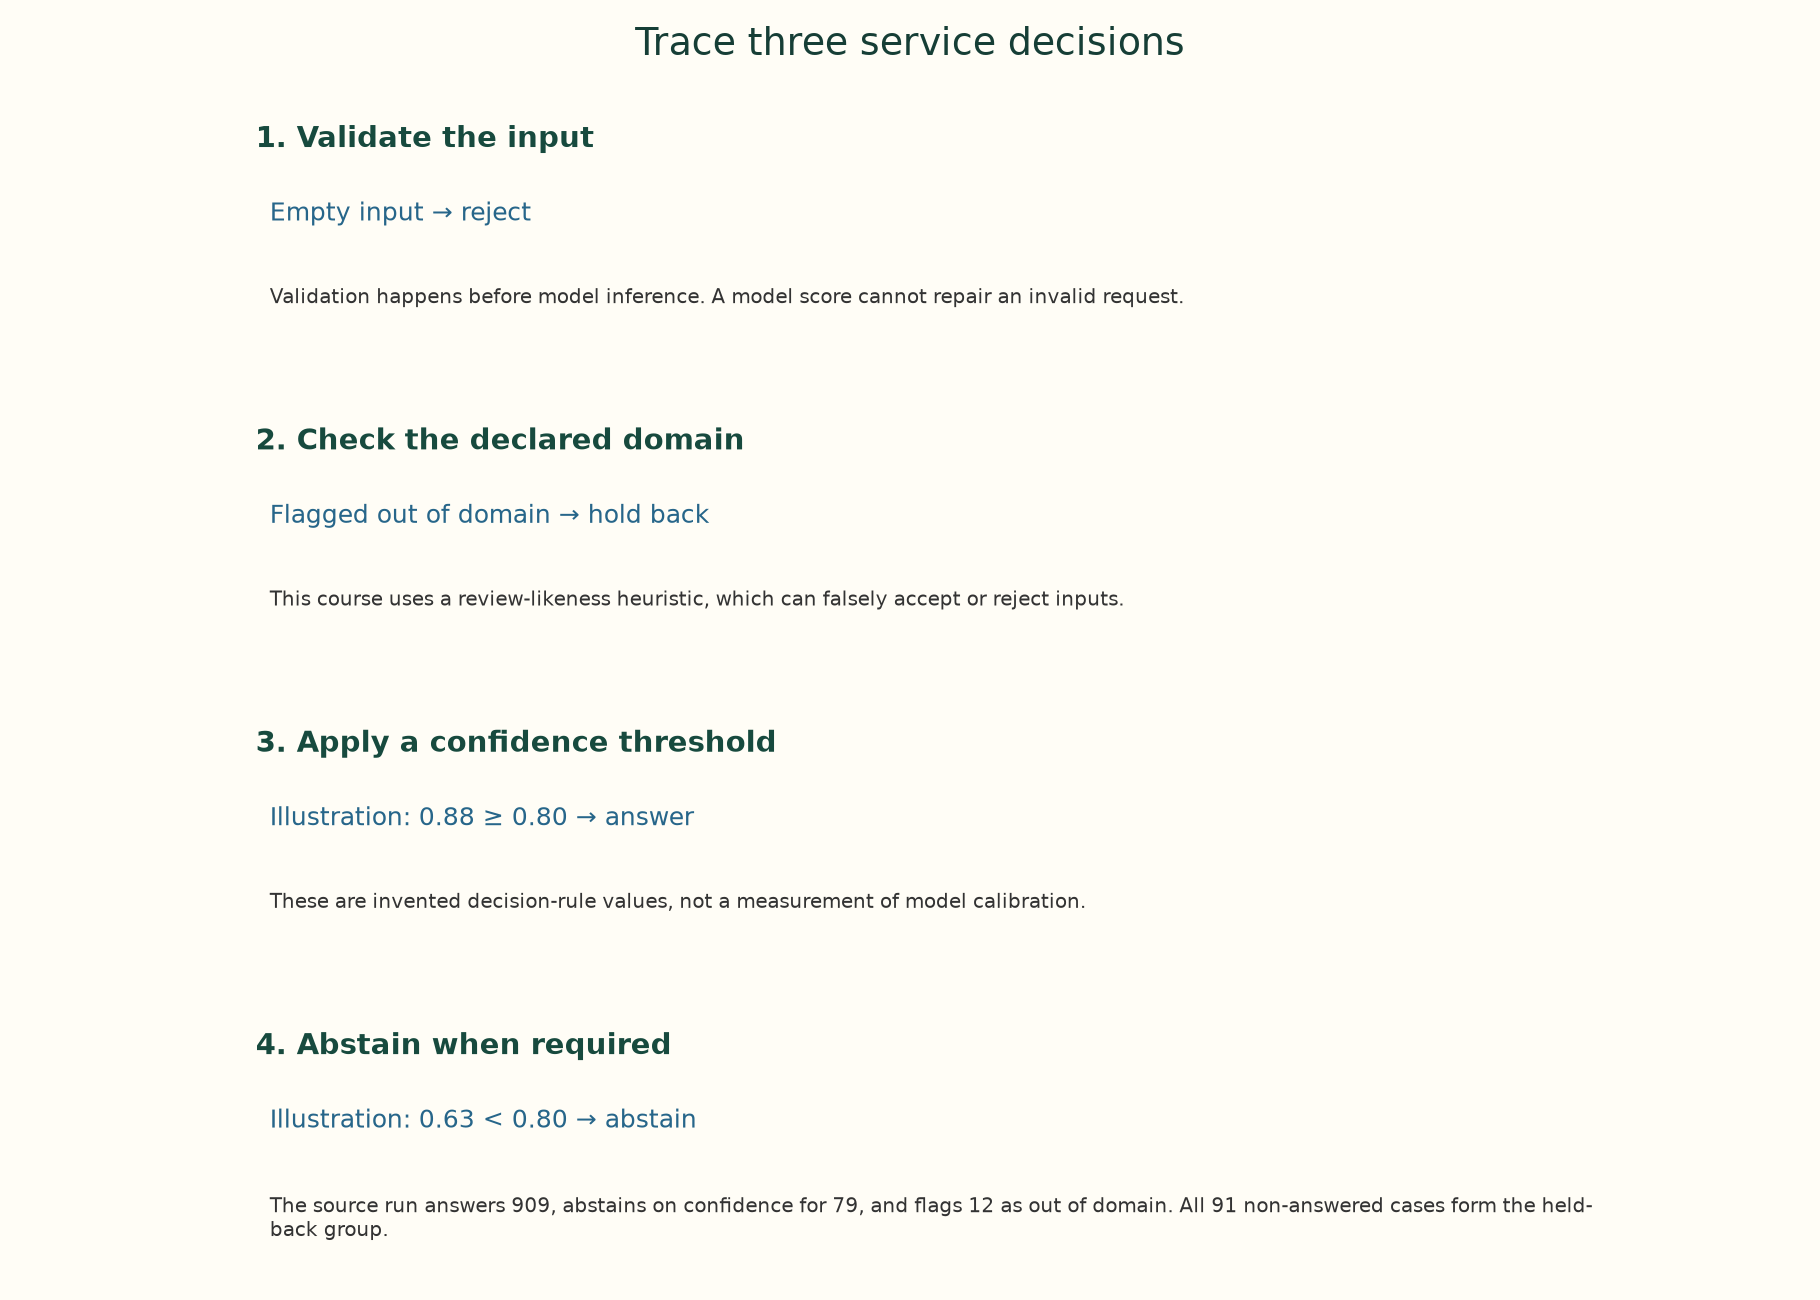

**1. Validate the input.** Empty input → reject. Validation happens before model inference. A model score cannot repair an invalid request.

**2. Check the declared domain.** Flagged out of domain → hold back. This course uses a review-likeness heuristic, which can falsely accept or reject inputs.

**3. Apply a confidence threshold.** Illustration: 0.88 ≥ 0.80 → answer. These are invented decision-rule values, not a measurement of model calibration.

**4. Abstain when required.** Illustration: 0.63 < 0.80 → abstain. The source run answers 909, abstains on confidence for 79, and flags 12 as out of domain. All 91 non-answered cases form the held-back group.

*The app adds a paused animation of this same supplied example.*

## 7. Evaluating Application-Level Performance

### 7.1 What the service does on unseen reviews

Now the test set, used once. We run the service on the 1,000 `test_eval` reviews. With 1,000 reviews, each review is worth 0.1 percentage points of accuracy.

In [20]:
test_x, test_y = imdb["test_eval"]
test_results = service.predict(test_x)
status = np.array([r["status"] for r in test_results])
pred = np.array([r["label"] == "POSITIVE" for r in test_results])
conf = np.array([r["confidence"] for r in test_results])
for s in ("ok", "abstain", "out_of_domain", "rejected", "error"):
    print(f"{s:<14} {(status == s).sum():>4}")
answered = status == "ok"
print(f"\naccuracy if we answered everything: {(pred == test_y).mean():.3f} ({len(test_y)} reviews; one review = {1 / len(test_y):.1%})")
print(f"coverage (share answered):          {answered.mean():.3f}")
print(f"accuracy on the answered reviews:   {(pred[answered] == test_y[answered]).mean():.3f}")
print(f"accuracy on the held-back reviews:  {(pred[~answered] == test_y[~answered]).mean():.3f}")

ok              909
abstain          79
out_of_domain    12
rejected          0
error             0

accuracy if we answered everything: 0.875 (1000 reviews; one review = 0.1%)
coverage (share answered):          0.909
accuracy on the answered reviews:   0.899
accuracy on the held-back reviews:  0.637


The service answered 909 reviews, abstained on 79 and flagged 12 genuine reviews as out of domain: about 1%, matching the rate we designed on validation. Three numbers describe the application:
- **Accuracy if we answered everything:** 0.875. This is the model's raw accuracy.
- **Coverage:** 0.909 of reviews were answered.
- **Accuracy on the answered reviews:** 0.899.

The held-back reviews really were the hard ones: the model would have got only 0.637 of them right. Abstention bought a higher accuracy on what we *do* answer at the cost of answering fewer reviews, and that is a product decision, not a technical one.

### 7.2 Which way the errors go

Accuracy hides *which* mistakes a model makes. A **confusion matrix** counts each combination of true and predicted label:

In [21]:
cm = np.zeros((2, 2), dtype=int)
for t, p_ in zip(test_y, pred.astype(int)):
    cm[t, p_] += 1
print("rows = true label, columns = predicted (0 = negative, 1 = positive), all 1,000 reviews:\n", cm)
print(f"recall on negative reviews {cm[0, 0] / cm[0].sum():.3f} | recall on positive reviews {cm[1, 1] / cm[1].sum():.3f}")

rows = true label, columns = predicted (0 = negative, 1 = positive), all 1,000 reviews:
 [[434  51]
 [ 74 441]]
recall on negative reviews 0.895 | recall on positive reviews 0.856


Of 485 negative reviews (434 + 51), 434 were recognised; of 515 positive reviews (74 + 441), 441 were. The model misses positive reviews more often than negative ones: a recall of 0.856 for positive against 0.895 for negative. If the feature exists to surface unhappy customers, missing 51 negative reviews matters more than the positive mistakes. If it exists to quote praise on a poster, the 74 missed positives matter more. The same model can be good enough for one feature and not the other.

### 7.3 The coverage–accuracy trade-off

Our threshold is one point on a continuum. If we rank the test reviews from most to least confident and answer only the top share, we get a curve:

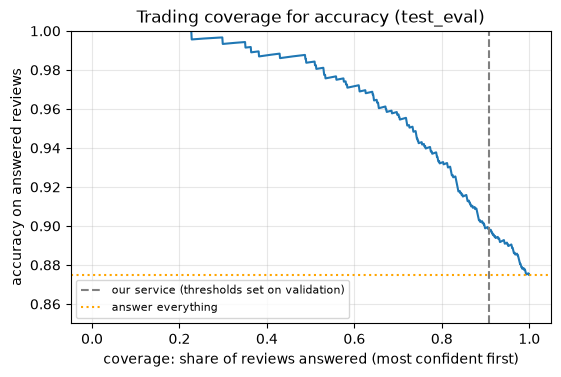

answer the 50% most confident: accuracy 0.984
answer the 80% most confident: accuracy 0.932
answer the 90% most confident: accuracy 0.899
answer the 100% most confident: accuracy 0.875


In [22]:
order = np.argsort(-conf, kind="stable")                              # most confident first
right = (pred == test_y)[order]
coverage = np.arange(1, len(order) + 1) / len(order)
acc_at = np.cumsum(right) / np.arange(1, len(order) + 1)              # accuracy if we answer the top-k most confident
plt.figure(figsize=(6.2, 3.8))
plt.plot(coverage, acc_at)
plt.axvline(answered.mean(), color="grey", ls="--", label=f"our service (thresholds set on validation)")
plt.axhline((pred == test_y).mean(), color="orange", ls=":", label="answer everything")
plt.xlabel("coverage: share of reviews answered (most confident first)"); plt.ylabel("accuracy on answered reviews")
plt.ylim(0.85, 1.0); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.title("Trading coverage for accuracy (test_eval)")
plt.show()
for c in (0.5, 0.8, 0.9, 1.0):
    k = int(c * len(order))
    print(f"answer the {c:.0%} most confident: accuracy {acc_at[k - 1]:.3f}")

The curve falls steadily as we answer more. Answering only the most confident half gives 0.984 accuracy; 80% gives 0.932; our service's point, about 90%, gives 0.899; answering everything gives 0.875. (The curve is jagged at the far left, where only a few reviews are answered.) This is the tool for a product conversation: "If people can review one review in ten, the model is right 0.899 of the time on the rest; if they can review half, 0.984."

### 7.4 Speed per request

Finally, how long does one request take? A request runs two models, the classifier and the review-likeness embedding.

In [23]:
one = [test_x[0]]
service.predict(one)                                                  # warm-up
t0 = benchmark_clock()
for _ in range(10):
    service.predict(one)
print(f"one request: {(benchmark_clock() - t0) / 10 * 1000:.1f} ms (classification + review-likeness check)")

one request: 34.3 ms (classification + review-likeness check)


Each request takes tens of milliseconds on this CPU (the printed time will differ on your machine). Note 7.6 looks at how latency, batching and hardware trade off in deployment.

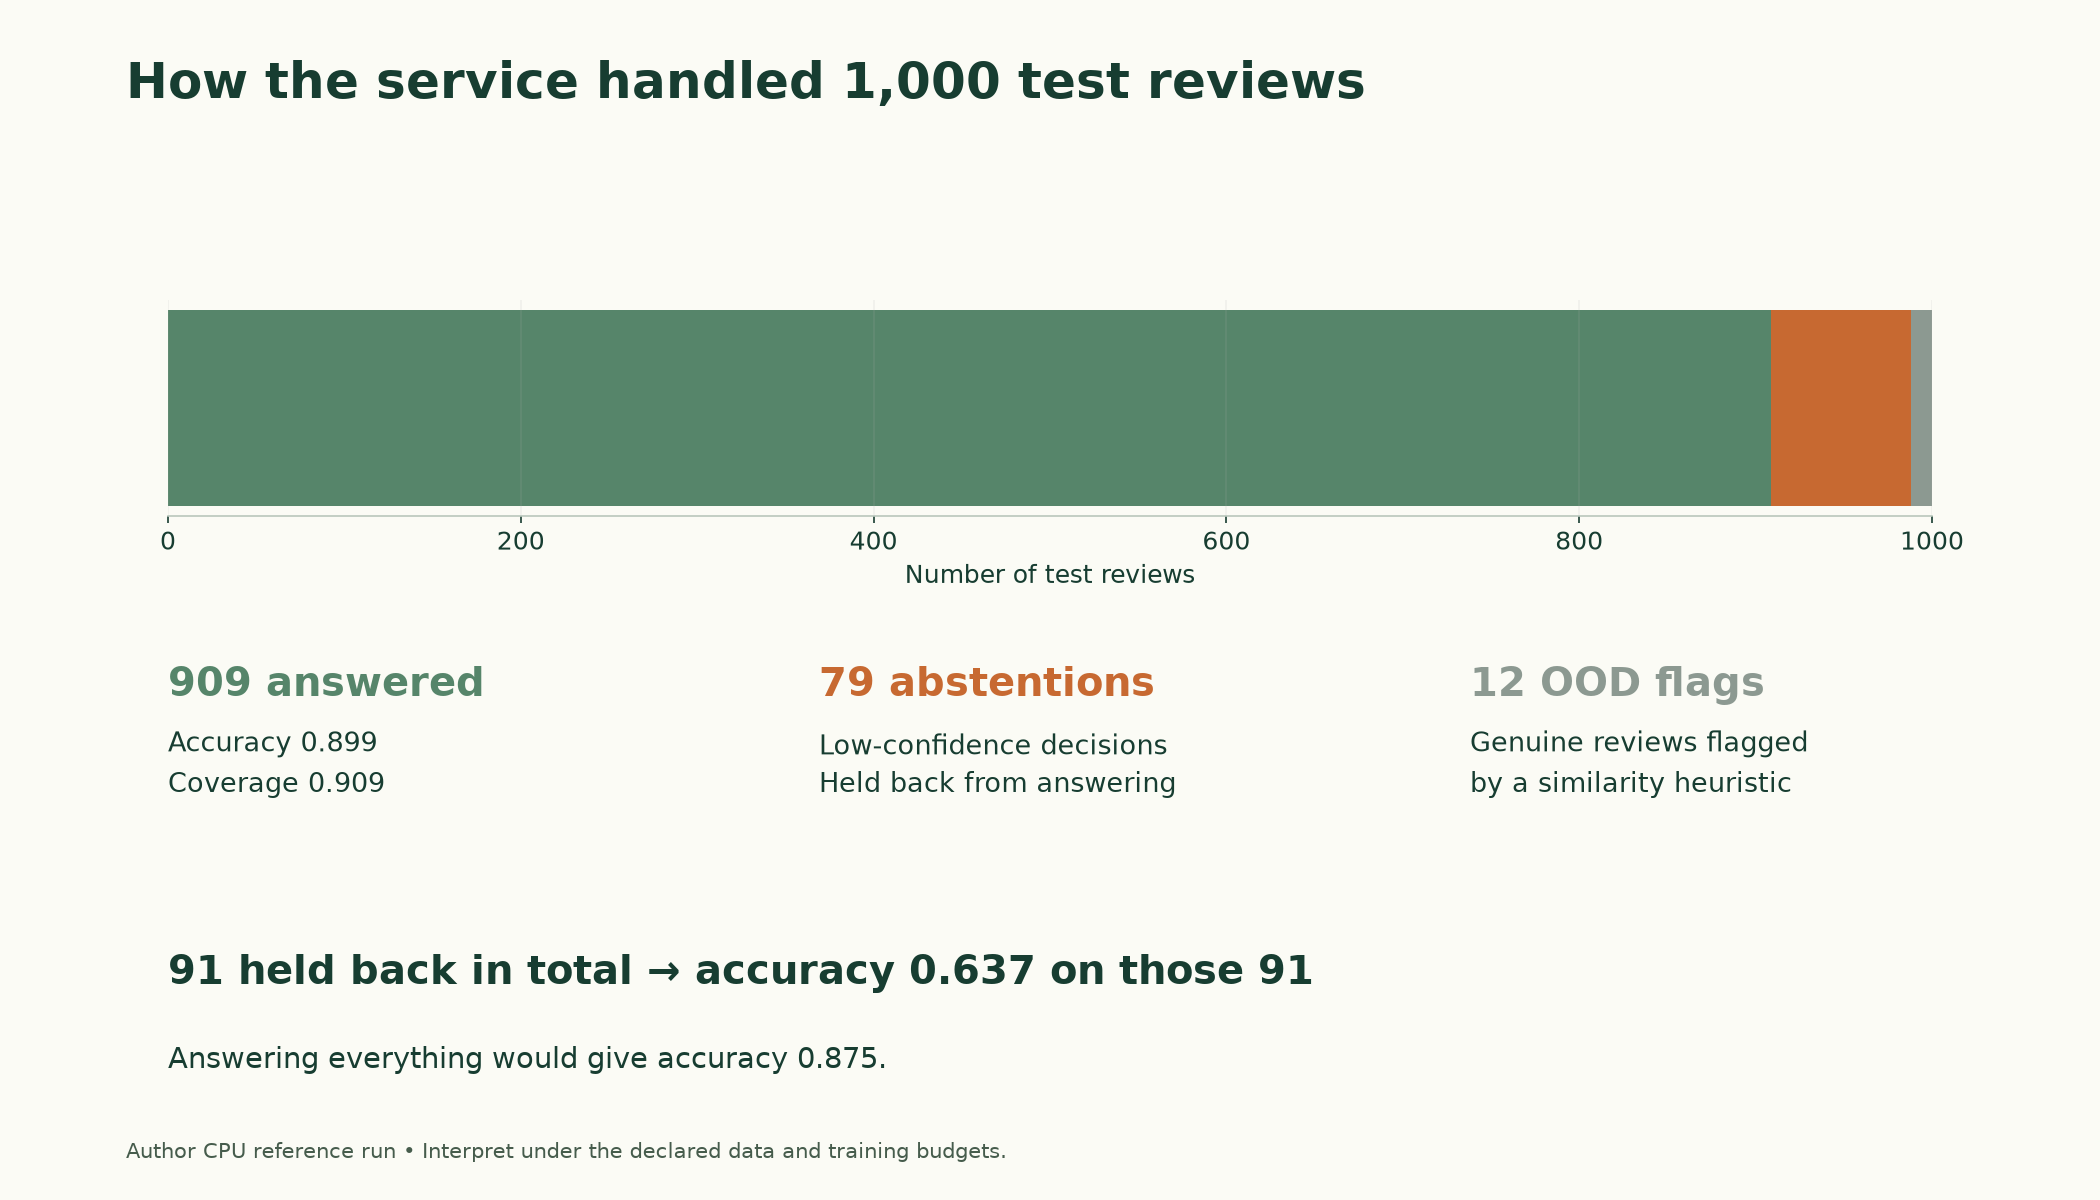

*Figure 7.5.2. Of 1,000 source test reviews, 909 were answered, 79 received a confidence abstention and 12 were flagged out of domain. Held-back accuracy 0.637 applies to all 91 non-answered reviews.*

> **Key terms**
> - **Coverage:** the share of inputs for which the system gives an answer.
> - **Selective accuracy:** accuracy measured only on the inputs the system answers.
> - **Confusion matrix:** a table counting each combination of true and predicted label.
> - **Recall (per class):** the share of a class's real examples that the model labels correctly.

> **Common mistake:** reporting only the model's accuracy for an application with abstention or filtering. Always report coverage alongside accuracy on answered inputs. A system that answers only its easiest 10% can show near-perfect accuracy and still be useless.

**Check yourself.**

1. A manager asks for "at least 0.95 accuracy". Using the coverage–accuracy numbers, what would you tell them, and what decision do they need to make?

<details>
<summary>Worked answer</summary>

Answering everything gives 0.875, below the target. On the coverage–accuracy curve, accuracy reaches 0.932 at 80% coverage and 0.984 at 50%, so 0.95 requires answering somewhere between half and four-fifths of reviews. The manager has to decide whether it's acceptable for people to handle the rest, and how many people that needs. Alternatively, the model must be improved, for example by fine-tuning it on IMDb data (Module 8).

</details>

## Putting It All Together

Let's reassemble what we built.

Four pretrained models gave four capabilities with a few lines each. The **sentiment model** scored 0.882 on validation, handled negation that defeated Note 5.3's model, but gave near-certain answers to lukewarm and nonsensical inputs: a confidence of 0.996 for "asdkjh qwe zzz". The **text generator** wrote fluent but invented text. Greedy decoding looped (repeated 3-word sequences: 0.18 on average), while temperature, top-k and top-p sampling didn't repeat in any of their 9 texts. The **sentence embeddings** found reviews by meaning, but rated "A dull, badly acted film" as close to "A thrilling, beautifully acted film" (0.737) as a true paraphrase was (0.734): they capture topic, not opinion. **CLIP** classified Fashion-MNIST zero-shot with 0.733 accuracy, recognising sneakers that Note 5.5's toy could not, once we chose inversion and a template on held-out images. It still failed on shirts.

Capabilities become features through an **application layer**: input checks, an out-of-domain check (embeddings, with a threshold set so 99% of genuine validation reviews pass), and abstention (the least confident tenth, set on validation). On 1,000 unseen reviews, the service answered 909 with 0.899 accuracy, against 0.875 for answering everything; the 91 it held back (79 abstentions plus 12 out-of-domain flags) would have been right only 0.637 of the time. The confusion matrix showed which way the errors go (positive recall 0.856, negative 0.895), and the coverage–accuracy curve turns the threshold into a product decision.

| Application | Model | What worked | What failed |
|---|---|---|---|
| Sentiment | DistilBERT (SST-2) | 0.882 on validation; negation | confident on lukewarm and nonsense inputs |
| Generation | distilgpt2 | fluent, varied text when sampling | greedy loops; invented facts |
| Semantic search | MiniLM | finds reviews by meaning | ranks by topic, not opinion |
| Zero-shot images | CLIP | 0.733 on Fashion-MNIST, sneakers 0.79 | shirts 0.15 |
| Sentiment service | DistilBERT + MiniLM | 0.899 accuracy at 0.909 coverage; OOD inputs flagged | confident mistakes on mixed reviews remain |

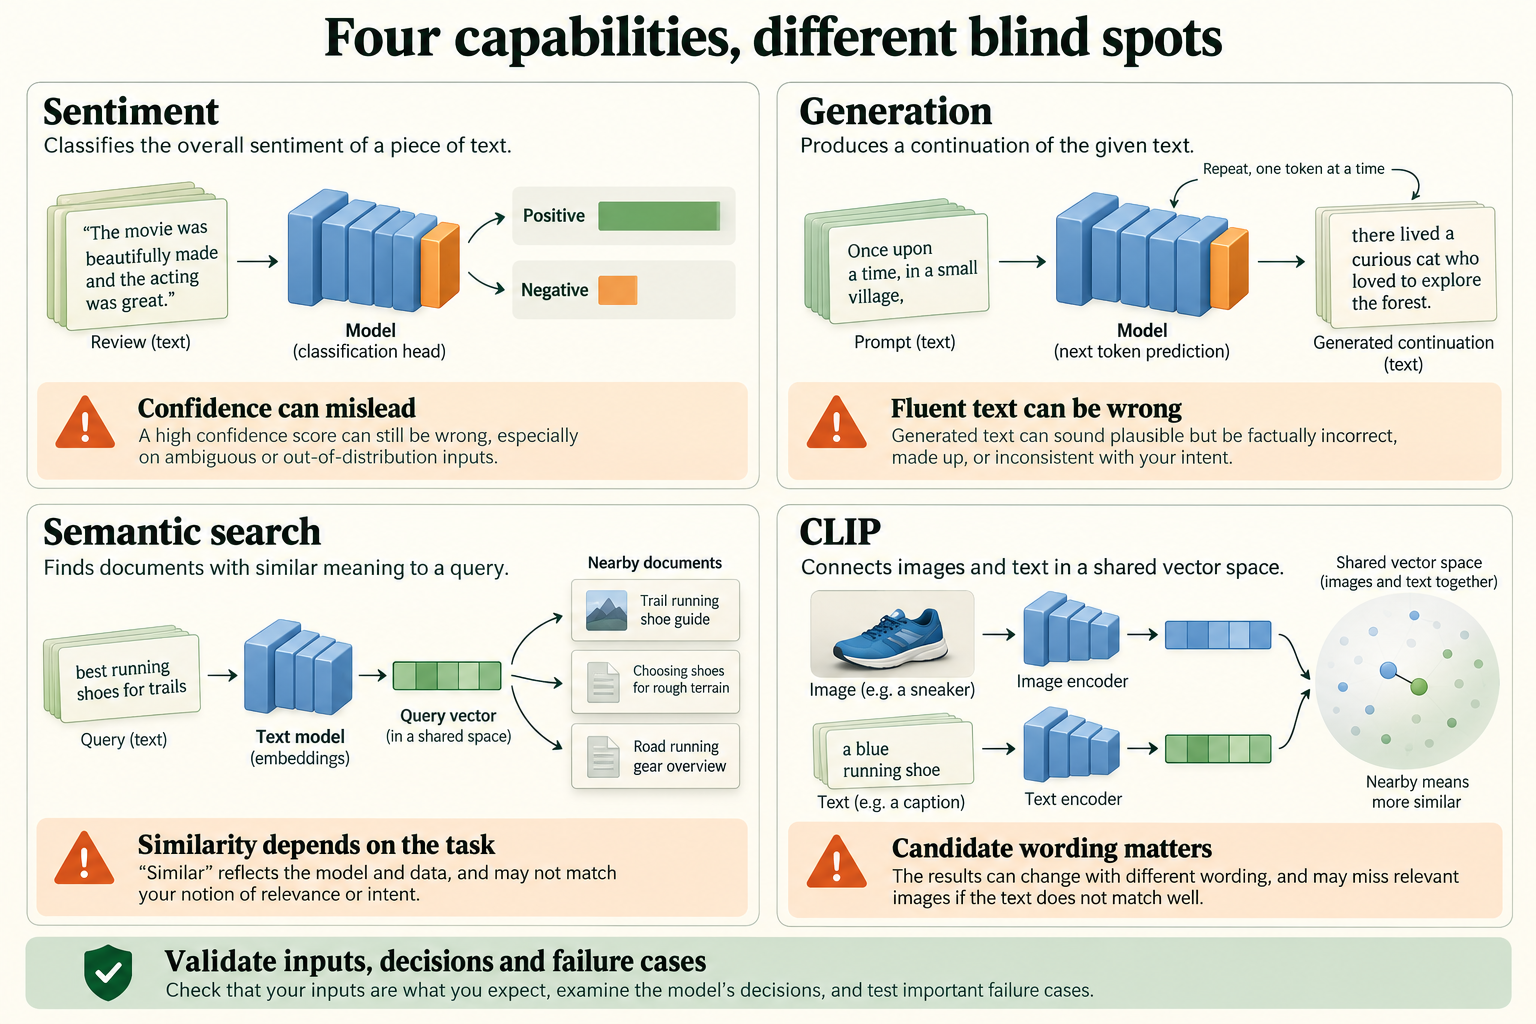

*Figure 7.5.3. Each capability has failure modes. The notebook measures particular examples; similarity, confidence and fluent generation do not by themselves establish correctness.*

> **Interpret the evidence carefully.** Here the 0.637 held-back accuracy applies to all 91 non-answered reviews, not just the 79 low-confidence abstentions. The semantic-similarity and repetition observations are results of these particular examples, models and settings, not universal properties of embeddings or sampling.

## Summary

- A pretrained model provides a **capability**; an **application** adds input checks, fit checks, decision rules and evaluation.
- The sentiment model scored 0.882 on validation and handled negation correctly, but was near-certain on lukewarm reviews and on nonsense (0.996 confidence for "asdkjh qwe zzz"). **Confidence does not mean an input made sense.**
- **Temperature** sharpens or flattens the next-token distribution. **Greedy decoding** looped and repeated itself; **sampling** with temperature, top-k or top-p produced varied text with no repeated 3-word sequences in any of 9 samples, though distilgpt2 invents facts.
- **Sentence embeddings** (MiniLM, mean pooling) power semantic search, but capture topic rather than opinion: an opposite-sentiment sentence scored 0.737, a paraphrase 0.734.
- **CLIP** reached 0.733 zero-shot accuracy on Fashion-MNIST, with inversion and template chosen on 300 separate images. Sneakers 0.79, shirts 0.15.
- A reusable **inference service** validates inputs, never lets one bad input break a batch, flags out-of-domain text with an embedding-similarity check, abstains on low confidence, and returns a status and reason for every input.
- On 1,000 test reviews: **coverage** 0.909, accuracy on answered reviews 0.899 (against 0.875 answering everything), and the held-back reviews would have been right only 0.637 of the time. Report coverage with accuracy, and use a **confusion matrix** to see which errors the model makes.

## Glossary

| Term | Meaning |
|---|---|
| Capability | What a model computes from an input. |
| Application layer | The code around a model: input checks, fit checks, decision rules, error handling. |
| Out-of-distribution (OOD) input | An input unlike the data a model was trained on. |
| Confidence | The probability a classifier gives to its chosen class. |
| Temperature | A divisor applied to logits before softmax, sharpening (below 1) or flattening (above 1) the distribution. |
| Greedy decoding | Always choosing the most likely next token. |
| Top-k sampling | Sampling from the k most likely tokens. |
| Top-p (nucleus) sampling | Sampling from the smallest set of tokens with total probability at least p. |
| Degenerate repetition | A generator getting stuck repeating words or tokens. |
| Sentence-embedding model | A model mapping a text to one vector so similar meanings are close. |
| Mean pooling | Averaging token vectors, ignoring padding, to get one vector per text. |
| Semantic search | Retrieving documents by similarity of meaning. |
| Zero-shot classification | Classifying into classes described in words, without training on them. |
| Prompt template | A sentence pattern used to describe each class, such as "a photo of a {}.". |
| Text-to-image retrieval | Finding images whose embeddings are closest to a text query's. |
| Inference service | A wrapper that turns a model into a dependable component with structured results. |
| Abstention | Declining to answer, usually because confidence is low. |
| Out-of-domain detection | Checking whether an input resembles the data a model was built for. |
| Threshold | The cut-off value in a decision rule, set on validation data. |
| Coverage | The share of inputs the system answers. |
| Selective accuracy | Accuracy on the answered inputs only. |
| Confusion matrix | A table counting each combination of true and predicted label. |
| Recall | The share of a class's real examples labelled correctly. |